<div style="background: linear-gradient(135deg, #114F6A 0%, #1FA4B1 100%); padding: 28px; border-radius: 12px; color: #FFFFFF; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; box-shadow: 0 4px 12px rgba(17, 79, 106, 0.2);">
  <h1 style="margin: 0; font-size: 26px; letter-spacing: 1px; color: #FFFFFF;">PROYEK UTS PRAKTIKUM DEEP LEARNING</h1>
  <p style="margin: 6px 0 20px 0; font-size: 14px; color: #E0F7FA; opacity: 0.95;">Implementasi Sequence Deep Learning (RNN / LSTM) untuk Analisis Sentimen & Time-Series Forecasting</p>
  
  <div style="background-color: #FFFFFF; color: #1E293B; padding: 18px 22px; border-radius: 8px; border-left: 6px solid #114F6A;">
    <h3 style="margin: 0 0 12px 0; color: #114F6A; font-size: 16px; border-bottom: 2px solid #E2E8F0; padding-bottom: 6px;">DATA DIRI & KONFIGURASI PROYEK</h3>
    <table style="width: 100%; border-collapse: collapse; font-size: 14px; color: #1E293B;">
      <tr>
        <td style="padding: 6px 0; width: 220px; font-weight: bold; color: #114F6A;">Nama Lengkap</td>
        <td style="padding: 6px 0;">: Asyla</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">NIM</td>
        <td style="padding: 6px 0;">: 202432069</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kelas</td>
        <td style="padding: 6px 0;">: B</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kategori Tugas (Sesuai NIM)</td>
        <td style="padding: 6px 0;">: Analisis Sentimen NLP (NIM Ganjil)</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Algoritma yang Dipilih</td>
        <td style="padding: 6px 0;">: <span style="background-color: #1FA4B1; color: #FFFFFF; padding: 2px 10px; border-radius: 4px; font-weight: bold;">LSTM</span></td>
      </tr>
    </table>
  </div>
</div>

#

#

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 12px;">
  <div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 16px; border-bottom: 4px solid #1FA4B1;">
    BAB 1 — LATAR BELAKANG MASALAH
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 20px; line-height: 1.7; font-size: 14px;">
    <p style="margin-top: 0;">
      <b>1. Deskripsi Permasalahan:</b><br>
      Livin' by Mandiri adalah aplikasi mobile banking Bank Mandiri yang dipakai nasabah untuk transfer, pembayaran, dan layanan perbankan lainnya. Pengguna menuliskan pengalamannya di kolom ulasan Google Play Store, mulai dari keluhan (verifikasi wajah gagal, aplikasi error, gagal login) sampai pujian (transfer cepat, mudah dipakai). Dengan puluhan hingga ratusan ribu ulasan, membaca satu per satu tidak mungkin dilakukan, sehingga klasifikasi sentimen otomatis dibutuhkan agar pengembang dapat memantau kepuasan pengguna dan menemukan masalah lebih cepat. Ulasan berbahasa Indonesia ditulis secara informal (singkatan, salah ketik, tanpa tanda baca) dan maknanya bergantung pada urutan kata, misalnya "tidak bagus" berlawanan dengan "bagus". Karena itu pendekatan Deep Learning yang membaca teks secara berurutan lebih sesuai dibanding sekadar menghitung kemunculan kata.
    </p>
    <p style="margin-bottom: 0;">
      <b>2. Tujuan Pemodelan & Alasan Pemilihan Algoritma:</b><br>
      <i>Tujuan:</i> membangun model klasifikasi sentimen tiga kelas (Negatif, Netral, Positif) pada ulasan aplikasi Livin' by Mandiri, lalu mengevaluasinya dengan akurasi, precision, recall, F1-score, dan confusion matrix. <i>Alasan memilih LSTM:</i> RNN biasa mudah kehilangan informasi kata di awal kalimat akibat vanishing gradient. LSTM memiliki cell state dan tiga gate (forget, input, output) yang mengatur informasi apa yang dibuang, disimpan, dan dikeluarkan pada setiap langkah waktu, sehingga negasi dan konteks kalimat lebih terjaga.
    </p>
  </div>
</div>

#

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: sans-serif; margin-top: 10px;">
<div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 15px; border-bottom: 4px solid #1FA4B1;">INFORMASI &amp; KARAKTERISTIK DATASET KAGGLE</div>
<div style="background-color: #F8FAFC; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
<div style="background-color: #E0F7FA; border-left: 5px solid #1FA4B1; padding: 12px 16px; border-radius: 4px; margin-bottom: 14px;">
<b style="color: #114F6A;">Nama Dataset:</b> Livin Mandiri App Reviews from Google Playstore<br>
<b style="color: #114F6A;">Link Dataset Kaggle:</b> <a href="https://www.kaggle.com/datasets/ahmadseloabadi/livin-mandiri-app-reviews-from-google-playstore" target="_blank" style="color: #114F6A; font-weight: bold; text-decoration: underline;">https://www.kaggle.com/datasets/ahmadseloabadi/livin-mandiri-app-reviews-from-google-playstore</a>
</div>
<div style="margin-bottom: 12px;">
<b style="color: #114F6A;">Penjelasan Umum Dataset:</b><br>
Dataset berisi ulasan aplikasi Livin' by Mandiri yang diambil (scraping) dari Google Play Store. File <code>scrapped_livin.csv</code> memiliki <b>174.931 baris</b> dan <b>4 kolom</b>: <code>userName</code> (anonim, seluruhnya bernilai "Pengguna Google" sehingga tidak dipakai), <code>score</code> (rating bintang 1-5), <code>at</code> (waktu ulasan, 30 Sep 2021 sampai 4 Des 2024), dan <code>content</code> (teks ulasan berbahasa Indonesia).<br>Distribusi rating: bintang 5 = 89.922; bintang 1 = 48.053; bintang 4 = 13.136; bintang 2 = 12.012; bintang 3 = 11.808.<br><b>Pelabelan sentimen</b> dari rating: bintang 1-2 = Negatif, bintang 3 = Netral, bintang 4-5 = Positif. Setelah pembersihan teks dan penghapusan duplikat tersisa 114.632 ulasan (Negatif 56.066, Netral 10.121, Positif 48.445). Agar kelas seimbang, diambil 10.000 ulasan per kelas (total 30.000) lalu dibagi 70% latih, 15% validasi, 15% uji.
</div>
</div>
</div>

#

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">1. IMPORT LIBRARY</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat pustaka komputasi numerik, manipulasi data, visualisasi grafik, dan kerangka kerja PyTorch.</p>
</div>

In [6]:
#202432069_Asyla Salsabil
import re
import copy
import random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Seed agar hasil dapat direproduksi
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Gunakan GPU jika tersedia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">2. PRA-PEMROSESAN DATA (PREPROCESSING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat dataset, membersihkan data, melakukan normalisasi / tokenisasi sekuens, serta membagi data latih dan data uji.</p>
</div>

Saving scrapped_livin.csv to scrapped_livin.csv
Jumlah baris & kolom awal: (174931, 4)
score
1    48053
2    12012
3    11808
4    13136
5    89922
Name: count, dtype: int64
Jumlah ulasan setelah dibersihkan & dedup: 114632
label
0    56066
1    10121
2    48445
Name: count, dtype: int64
Data seimbang: 30000 ulasan, per kelas 10000
Latih/Validasi/Uji: 21000 4500 4500
Ukuran vocabulary: 6255
Contoh teks : aq tuh sudah jadi nasabah mandiri sejak aq puas bgt sm pelayanan bank mandiri dalam hal aplikasi aksesnya mudah banget aplg skrg jd makin lbh mudah klo slh password prnh sekali salah password x berturut krna hp error gag perlu k cs klo mw reset ulang password jd bs sndiri pake email qta trus aq suka fitur aplikasi ini lengkap dan mudah bgt dgunakan blm lg nominal transfernya bs diatas jt sehari utk sesama mandiri ataupun antar bank pokoknya keren bgt deh
Contoh indeks: [824, 628, 24, 45, 138, 13, 592, 824, 343, 170, 962, 290, 41, 13, 114, 353, 6, 1404, 47, 58, 1, 309, 174, 81, 410, 47,

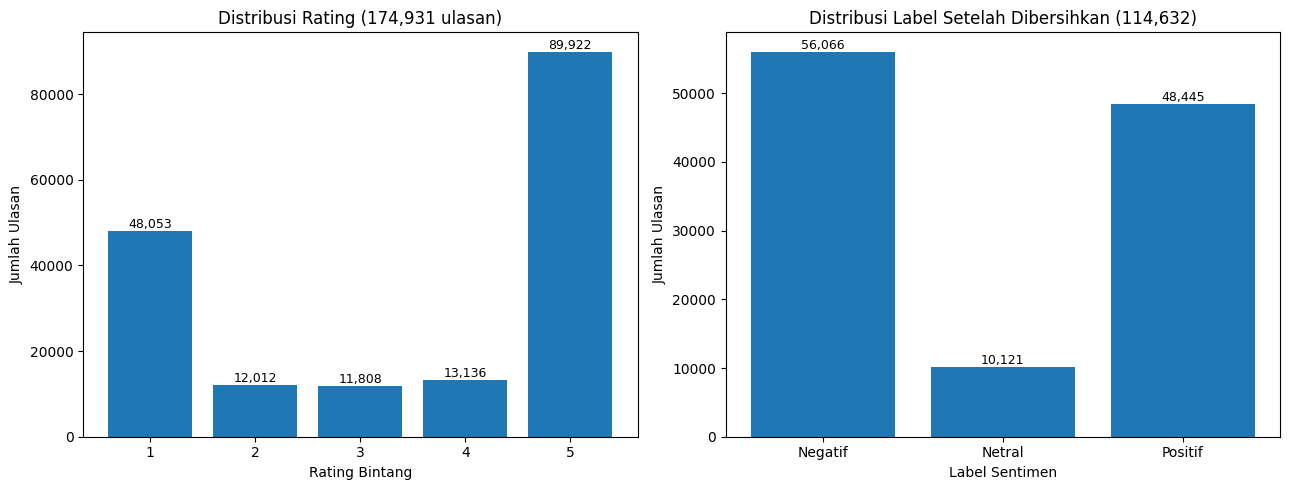

In [7]:
#202432069_Asyla Salsabil
# 1. Muat dataset
import pandas as pd
import re

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('scrapped_livin.csv')

# Simpan dataset asli sebelum preprocessing
df_awal = df.copy()

print('Jumlah baris & kolom awal:', df.shape)
print(df['score'].value_counts().sort_index())

# 2. Pelabelan sentimen dari rating: 1-2 = Negatif, 3 = Netral, 4-5 = Positif
LABELS = ['Negatif', 'Netral', 'Positif']

def beri_label(score):
    if score <= 2:
        return 0
    elif score == 3:
        return 1
    else:
        return 2

df['label'] = df['score'].apply(beri_label)

# 3. Pembersihan teks: case folding, hapus URL, hapus angka/simbol/emoji, rapikan spasi
def bersihkan_teks(teks):
    teks = str(teks).lower()
    teks = re.sub(r'http\S+|www\.\S+', ' ', teks)
    teks = re.sub(r'[^a-z\s]', ' ', teks)
    teks = re.sub(r'\s+', ' ', teks).strip()
    return teks

df['clean'] = df['content'].apply(bersihkan_teks)
df = df[df['clean'] != ''].drop_duplicates(subset='clean').reset_index(drop=True)
print('Jumlah ulasan setelah dibersihkan & dedup:', len(df))
print(df['label'].value_counts().sort_index())

# 4. Sampling seimbang: ambil jumlah sama untuk tiap kelas, lalu acak urutan
n_per_class = min(10000, df['label'].value_counts().min())
df_bal = pd.concat([df[df['label'] == k].sample(n=n_per_class, random_state= SEED) for k in range(3)])
df_bal = df_bal.sample(frac=1, random_state=SEED).reset_index(drop=True)
print('Data seimbang:', len(df_bal), 'ulasan, per kelas', n_per_class)

# 5. Bagi data: 70% latih, 15% validasi, 15% uji (stratified)
X_text = df_bal['clean'].values
y_all = df_bal['label'].values
X_tr_txt, X_tmp_txt, y_tr, y_tmp = train_test_split(X_text, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val_txt, X_te_txt, y_val, y_te = train_test_split(X_tmp_txt, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print('Latih/Validasi/Uji:', len(X_tr_txt), len(X_val_txt), len(X_te_txt))

# 6. Tokenisasi & vocabulary mapping (hanya dari data latih agar tidak bocor)
MAX_VOCAB = 10000
MAX_LEN = 40
counter = Counter(w for teks in X_tr_txt for w in teks.split())
kata_umum = [w for w, c in counter.most_common(MAX_VOCAB - 2) if c >= 2]
word2idx = {'<PAD>': 0, '<UNK>': 1}
for w in kata_umum:
    word2idx[w] = len(word2idx)
vocab_size = len(word2idx)
print('Ukuran vocabulary:', vocab_size)

# 7. Ubah teks menjadi urutan indeks + padding di kiri (agar token terakhir = kata terakhir asli)
def teks_ke_indeks(teks):
    ids = [word2idx.get(w, 1) for w in teks.split()][:MAX_LEN]
    return [0] * (MAX_LEN - len(ids)) + ids

contoh = X_tr_txt[0]
print('Contoh teks :', contoh)
print('Contoh indeks:', teks_ke_indeks(contoh))

# 8. Konversi ke PyTorch Tensor dan buat DataLoader
X_train = torch.tensor([teks_ke_indeks(t) for t in X_tr_txt], dtype=torch.long)
y_train = torch.tensor(y_tr, dtype=torch.long)
X_val = torch.tensor([teks_ke_indeks(t) for t in X_val_txt], dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
X_test = torch.tensor([teks_ke_indeks(t) for t in X_te_txt], dtype=torch.long)
y_test = torch.tensor(y_te, dtype=torch.long)
print('Bentuk X_train:', tuple(X_train.shape), '| y_train:', tuple(y_train.shape))

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val_t), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)


# 9. Visualisasi Distribusi Rating dan Label Sentimen

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Grafik 1: Distribusi rating dataset asli
rating_count = df_awal['score'].value_counts().sort_index()

ax[0].bar(rating_count.index.astype(str), rating_count.values)
ax[0].set_title(f'Distribusi Rating ({len(df_awal):,} ulasan)')
ax[0].set_xlabel('Rating Bintang')
ax[0].set_ylabel('Jumlah Ulasan')

for i, v in enumerate(rating_count.values):
    ax[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)

# Grafik 2: Distribusi label setelah pembersihan
label_count = df['label'].value_counts().sort_index()

ax[1].bar(
    ['Negatif', 'Netral', 'Positif'],
    [label_count.get(i, 0) for i in range(3)]
)
ax[1].set_title(f'Distribusi Label Setelah Dibersihkan ({len(df):,})')
ax[1].set_xlabel('Label Sentimen')
ax[1].set_ylabel('Jumlah Ulasan')

for i, v in enumerate([label_count.get(i, 0) for i in range(3)]):
    ax[1].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">3. PEMODELAN ARSITEKTUR JARINGAN (RNN / LSTM)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Mendefinisikan kelas arsitektur model sekuensial menggunakan modul torch.nn sesuai algoritma yang dipilih.</p>
</div>

In [8]:
#202432069_Asyla Salsabil
class SequenceModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_classes, dropout=0.3):
        super(SequenceModel, self).__init__()
        # Embedding: indeks kata -> vektor padat (indeks 0 = PAD tidak ikut dilatih)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # LSTM satu lapis; batch_first=True -> input berbentuk (batch, panjang_kalimat, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_size, batch_first=True)
        # Dropout untuk mengurangi overfitting
        self.dropout = nn.Dropout(dropout)
        # Layer linear: hidden state akhir -> skor 3 kelas
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        emb = self.embedding(x)              # (batch, MAX_LEN, embed_dim)
        out, (h_n, c_n) = self.lstm(emb)     # h_n: (1, batch, hidden_size)
        h_akhir = h_n[-1]                    # hidden state pada langkah waktu terakhir
        return self.fc(self.dropout(h_akhir))  # logits (batch, num_classes)

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">4. INISIASI HYPERPARAMETER & PROSES PELATIHAN (TRAINING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menentukan konfigurasi hyperparameter (learning rate, epochs, loss function, optimizer) dan menjalankan siklus pelatihan model.</p>
</div>

In [9]:
#202432069_Asyla Salsabil
# 1. Inisiasi hyperparameter
epochs = 10
learning_rate = 0.001
embed_dim = 64
hidden_size = 64
num_classes = 3

# 2. Inisiasi model, fungsi Loss (CrossEntropyLoss), dan Optimizer (Adam)
model = SequenceModel(vocab_size, embed_dim, hidden_size, num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
print(model)
print('Jumlah parameter:', sum(p.numel() for p in model.parameters()))

# 3. Simpan riwayat nilai loss & akurasi untuk divisualisasikan
train_losses, val_losses = [], []
train_accs, val_accs = [], []

def evaluasi(loader):
    model.eval()
    total_loss, benar, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * xb.size(0)
            benar += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
    return total_loss / total, benar / total

# 4. Training Loop (simpan bobot terbaik berdasarkan loss validasi)
best_val_loss = float('inf')
best_state = copy.deepcopy(model.state_dict())

for epoch in range(epochs):
    model.train()
    run_loss, run_benar, run_total = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        run_loss += loss.item() * xb.size(0)
        run_benar += (logits.argmax(dim=1) == yb).sum().item()
        run_total += xb.size(0)
    tr_loss, tr_acc = run_loss / run_total, run_benar / run_total
    va_loss, va_acc = evaluasi(val_loader)
    train_losses.append(tr_loss)
    val_losses.append(va_loss)
    train_accs.append(tr_acc)
    val_accs.append(va_acc)
    if va_loss < best_val_loss:
        best_val_loss = va_loss
        best_state = copy.deepcopy(model.state_dict())
    print(f'Epoch {epoch+1:02d}/{epochs} | Train Loss {tr_loss:.4f} Acc {tr_acc:.4f} | Val Loss {va_loss:.4f} Acc {va_acc:.4f}')

SequenceModel(
  (embedding): Embedding(6255, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)
Jumlah parameter: 433795
Epoch 01/10 | Train Loss 0.9666 Acc 0.5021 | Val Loss 0.8777 Acc 0.5587
Epoch 02/10 | Train Loss 0.8556 Acc 0.5867 | Val Loss 0.8428 Acc 0.5833
Epoch 03/10 | Train Loss 0.8082 Acc 0.6157 | Val Loss 0.8122 Acc 0.6111
Epoch 04/10 | Train Loss 0.7694 Acc 0.6459 | Val Loss 0.8029 Acc 0.6213
Epoch 05/10 | Train Loss 0.7395 Acc 0.6660 | Val Loss 0.7921 Acc 0.6360
Epoch 06/10 | Train Loss 0.7087 Acc 0.6829 | Val Loss 0.8016 Acc 0.6269
Epoch 07/10 | Train Loss 0.6809 Acc 0.6983 | Val Loss 0.8045 Acc 0.6331
Epoch 08/10 | Train Loss 0.6534 Acc 0.7147 | Val Loss 0.8273 Acc 0.6282
Epoch 09/10 | Train Loss 0.6263 Acc 0.7294 | Val Loss 0.8627 Acc 0.6229
Epoch 10/10 | Train Loss 0.6074 Acc 0.7440 | Val Loss 0.8615 Acc 0.6273


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">5. VISUALISASI LOSS TRAINING & PERBANDINGAN PREDIKSI VS AKTUAL</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menampilkan grafik konvergensi nilai Loss terhadap Epoch dan grafik evaluasi perbandingan hasil prediksi model terhadap data aktual.</p>
</div>

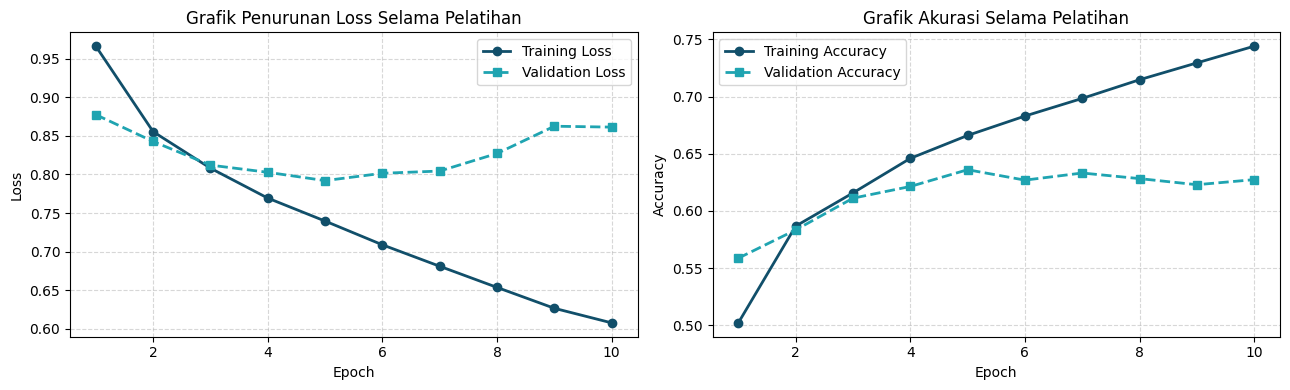

Akurasi data uji: 0.6233
              precision    recall  f1-score   support

     Negatif     0.5975    0.5760    0.5866      1500
      Netral     0.5069    0.5413    0.5235      1500
     Positif     0.7775    0.7527    0.7649      1500

    accuracy                         0.6233      4500
   macro avg     0.6273    0.6233    0.6250      4500
weighted avg     0.6273    0.6233    0.6250      4500



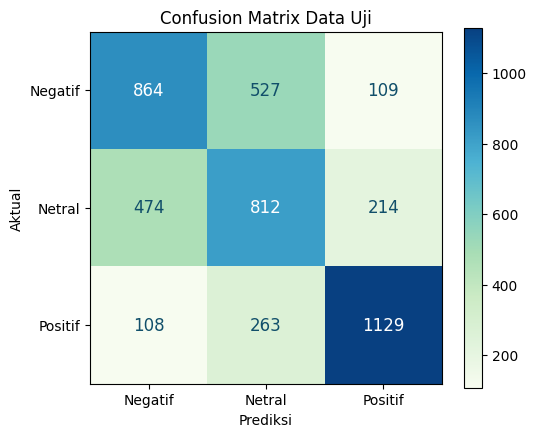

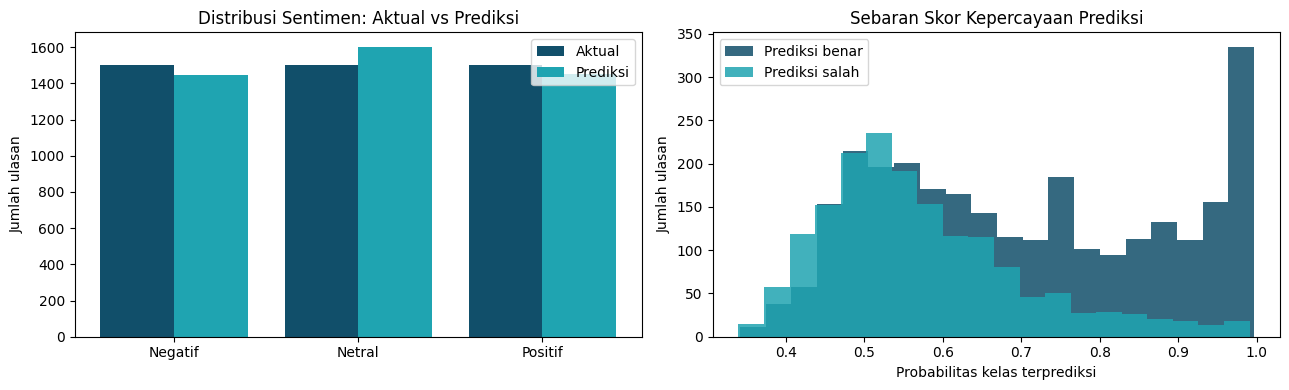

,Ulasan,Prediksi,Skor Negatif,Skor Netral,Skor Positif
0,"Aplikasinya bagus banget, transfer cepat dan mudah dipakai",Positif,0.0004,0.0117,0.9879
1,"Sering error, verifikasi wajah gagal terus, sangat mengecewakan",Negatif,0.7431,0.2254,0.0315
2,"Biasa saja, tidak ada yang spesial",Negatif,0.3853,0.3299,0.2848
3,"Tidak bisa login dari kemarin, tolong diperbaiki",Netral,0.3460,0.6028,0.0512


In [10]:
#202432069_Asyla Salsabil
# 1. Plot Grafik Penurunan Loss & Akurasi Training terhadap Epoch
rentang = range(1, len(train_losses) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(rentang, train_losses, color='#114F6A', linewidth=2, marker='o', label='Training Loss')
ax[0].plot(rentang, val_losses, color='#1FA4B1', linewidth=2, marker='s', linestyle='--', label='Validation Loss')
ax[0].set_title('Grafik Penurunan Loss Selama Pelatihan')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].legend()
ax[1].plot(rentang, train_accs, color='#114F6A', linewidth=2, marker='o', label='Training Accuracy')
ax[1].plot(rentang, val_accs, color='#1FA4B1', linewidth=2, marker='s', linestyle='--', label='Validation Accuracy')
ax[1].set_title('Grafik Akurasi Selama Pelatihan')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].grid(True, linestyle='--', alpha=0.5)
ax[1].legend()
plt.tight_layout()
plt.show()

# 2. Evaluasi pada data uji memakai bobot terbaik
model.load_state_dict(best_state)
model.eval()
semua_prob, semua_true = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        semua_prob.append(torch.softmax(model(xb.to(device)), dim=1).cpu())
        semua_true.append(yb)
probs = torch.cat(semua_prob).numpy()
y_true = torch.cat(semua_true).numpy()
y_pred = probs.argmax(axis=1)
print(f'Akurasi data uji: {accuracy_score(y_true, y_pred):.4f}')
print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))

# 3. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap='GnBu')
plt.colorbar()
plt.xticks(range(3), LABELS)
plt.yticks(range(3), LABELS)
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else '#114F6A', fontsize=12)
plt.title('Confusion Matrix Data Uji')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

# 4. Distribusi hasil prediksi sentimen dan skor kepercayaan (probabilitas tertinggi)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(3)
ax[0].bar(x - 0.2, np.bincount(y_true, minlength=3), width=0.4, color='#114F6A', label='Aktual')
ax[0].bar(x + 0.2, np.bincount(y_pred, minlength=3), width=0.4, color='#1FA4B1', label='Prediksi')
ax[0].set_xticks(x)
ax[0].set_xticklabels(LABELS)
ax[0].set_title('Distribusi Sentimen: Aktual vs Prediksi')
ax[0].set_ylabel('Jumlah ulasan')
ax[0].legend()
skor = probs.max(axis=1)
ax[1].hist(skor[y_pred == y_true], bins=20, color='#114F6A', alpha=0.85, label='Prediksi benar')
ax[1].hist(skor[y_pred != y_true], bins=20, color='#1FA4B1', alpha=0.85, label='Prediksi salah')
ax[1].set_title('Sebaran Skor Kepercayaan Prediksi')
ax[1].set_xlabel('Probabilitas kelas terprediksi')
ax[1].set_ylabel('Jumlah ulasan')
ax[1].legend()
plt.tight_layout()
plt.show()

# 5. Contoh prediksi pada ulasan baru beserta skor tiap kelas
def prediksi_sentimen(kalimat):
    ids = torch.tensor([teks_ke_indeks(bersihkan_teks(kalimat))], dtype=torch.long).to(device)
    with torch.no_grad():
        p = torch.softmax(model(ids), dim=1).cpu().numpy()[0]
    return LABELS[p.argmax()], p

contoh_kalimat = [
    'Aplikasinya bagus banget, transfer cepat dan mudah dipakai',
    'Sering error, verifikasi wajah gagal terus, sangat mengecewakan',
    'Biasa saja, tidak ada yang spesial',
    'Tidak bisa login dari kemarin, tolong diperbaiki',
]
tabel = []
for k in contoh_kalimat:
    label, p = prediksi_sentimen(k)
    tabel.append({'Ulasan': k, 'Prediksi': label, 'Skor Negatif': round(float(p[0]), 4),
                  'Skor Netral': round(float(p[1]), 4), 'Skor Positif': round(float(p[2]), 4)})
pd.set_option('display.max_colwidth', 70)
pd.DataFrame(tabel)

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <div style="background-color: #1FA4B1; color: #FFFFFF; padding: 10px 20px; font-weight: bold; font-size: 15px;">
    RINGKASAN ANALISIS PERFORMA MODEL
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
    <p style="margin: 0;">
      <b>Kesimpulan Hasil Visualisasi:</b><br>
Berdasarkan hasil visualisasi, model menunjukkan proses pembelajaran yang cukup baik, terlihat dari nilai Training Loss yang terus menurun dari sekitar 0,96 menjadi 0,61. Namun, Validation Loss mengalami penurunan pada awal pelatihan dan kembali meningkat pada epoch berikutnya. Hal ini menunjukkan adanya indikasi *overfitting*, yaitu ketika model semakin baik mengenali data latih tetapi belum mampu melakukan generalisasi dengan optimal pada data baru.

Hasil evaluasi pada data uji memperoleh akurasi sebesar **62,33%** dengan nilai F1-score keseluruhan sebesar **0,6250**. Berdasarkan classification report, kelas Positif memiliki performa terbaik dengan precision 0,7775, recall 0,7527, dan F1-score 0,7649. Sementara itu, kelas Netral memiliki performa terendah dengan F1-score 0,5235.

Berdasarkan Confusion Matrix, model paling banyak memprediksi dengan benar pada kelas Positif sebanyak 1.129 data, diikuti kelas Negatif sebanyak 864 data dan kelas Netral sebanyak 812 data. Kesalahan prediksi paling banyak terjadi pada data Negatif yang diprediksi sebagai Netral, yaitu sebanyak 527 data. Hal ini menunjukkan bahwa model masih kesulitan membedakan sentimen Negatif dan Netral.

Pada visualisasi distribusi sentimen, hasil prediksi menunjukkan jumlah kelas Netral lebih tinggi dibandingkan data aktual, sedangkan kelas Negatif dan Positif cenderung lebih rendah. Selain itu, grafik skor kepercayaan menunjukkan bahwa prediksi yang benar umumnya memiliki probabilitas lebih tinggi dibandingkan prediksi yang salah.

Secara keseluruhan, model sudah mampu mengklasifikasikan sentimen ulasan aplikasi Livin' ke dalam tiga kategori, yaitu Negatif, Netral, dan Positif. Namun, performanya masih perlu ditingkatkan, terutama dalam membedakan sentimen Negatif dan Netral serta mengurangi indikasi overfitting agar hasil prediksi menjadi lebih akurat dan konsisten.
    </p>
  </div>
</div>